<img src="MUML_header.svg" alt="Header" style="width:100%; height:auto;">

In this lab you will explore PyTorch's `torch.optim` library, including several optimizers and learning-rate schedulers by training the same neural network (fixed architecture). The goal is to understand optimizer behavior, sensitivity to hyperparameters (learning rate, momentum, weight decay, etc.) and the effect of schedulers.

You have to repeat the experiment with two different datasets. For the first one, the architecture of the neural network has to be the one of the linear regression. The second one has to be more complex, with at least a hidden layer (number of hidden layers and their size is up to you). For each problem, the architecture has to be fixed for all the experiments. Both proposed problems are regression ones, so use the MSELoss.

You have to compare at least the optimizers studied in class, but can add extra ones if you want. For learning rate schedulers, check at least three policies, the ones that you prefer.

Prepare a short written report in which you include  the best configurations for each optimizer. Add plots to show how the losses decrease, in order to compare them. For at least one optimizer, add a plot to compare the different learning rate schedulers you hace chosen.

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, TensorDataset

#### Dataset 1
`X1` and `y1` are the variables containing the dataset.

In [2]:
torch.manual_seed(42)

# --- Simular un dataset grande ---
N = 10000
X1 = torch.randn(N, 10)  # 10 features
true_w = torch.randn(10, 1)
true_b = 5.0

y1 = X1 @ true_w + true_b + 0.1 * torch.randn(N, 1)  # Regresión lineal con ruido

#### Dataset 2
`X2` and `y2` are the variables containing the dataset.

In [3]:
torch.manual_seed(0)

# --- Dataset complejo y no lineal ---
N = 10000
X2 = torch.randn(N, 20)

# Función objetivo complicada
y2 = (
    torch.sin(X2[:, 0] * X2[:, 1]) +
    torch.log(torch.abs(X2[:, 2]) + 1) * X2[:, 3] +
    torch.cos(X2[:, 4] + X2[:, 5]**2) +
    0.1 * torch.randn(N)
).unsqueeze(1)

For the first one, the architecture of the neural network has to be the one of the linear regression. The second one has to be more complex, with at least a hidden layer (number of hidden layers and their size is up to you).

In [4]:
class LinearModel(nn.Module):
    """Linear regression model for Problem 1."""
    def __init__(self, in_features=10):
        super().__init__()
        self.linear = nn.Linear(in_features, 1)

    def forward(self, x):
        return self.linear(x)

class NonLinearMLP(nn.Module):
    """Deep neural network with hidden layers for Problem 2."""
    def __init__(self, in_features=20):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_features, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, 1)
        )

    def forward(self, x):
        return self.net(x)

In [5]:
def train_model(model_cls, train_loader, opt_config, scheduler_cls=None, scheduler_kwargs=None, epochs=30):
    """
    Trains a fresh instance of model_cls using given optimizer and optional scheduler.
    Returns epoch loss history and learning rate history per epoch.
    """
    torch.manual_seed(42)
    model = model_cls()
    criterion = nn.MSELoss()
    
    opt_type = opt_config['type']
    opt_kwargs = {k: v for k, v in opt_config.items() if k != 'type'}
    optimizer = opt_type(model.parameters(), **opt_kwargs)
    
    scheduler = None
    if scheduler_cls is not None:
        scheduler_kwargs = scheduler_kwargs or {}
        scheduler = scheduler_cls(optimizer, **scheduler_kwargs)
        
    epoch_losses = []
    lr_history = []

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        
        for X_batch, y_batch in train_loader:
            optimizer.zero_grad()
            predictions = model(X_batch)
            loss = criterion(predictions, y_batch)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * X_batch.size(0)
            
        epoch_loss = running_loss / len(train_loader.dataset)
        epoch_losses.append(epoch_loss)
        lr_history.append(optimizer.param_groups[0]['lr'])
        
        # Step scheduler
        if scheduler is not None:
            if isinstance(scheduler, optim.lr_scheduler.ReduceLROnPlateau):
                scheduler.step(epoch_loss)
            else:
                scheduler.step()
                
    return epoch_losses, lr_history

In [6]:
X1 = torch.randn(N, 10)
true_w = torch.randn(10, 1)
true_b = 5.0
y1 = X1 @ true_w + true_b + 0.1 * torch.randn(N, 1)

dataset1 = TensorDataset(X1, y1)
train_loader1 = DataLoader(dataset1, batch_size=64, shuffle=True)

torch.manual_seed(0)
X2 = torch.randn(N, 20)
y2 = (
    torch.sin(X2[:, 0] * X2[:, 1]) +
    torch.log(torch.abs(X2[:, 2]) + 1) * X2[:, 3] +
    torch.cos(X2[:, 4] + X2[:, 5]**2) +
    0.1 * torch.randn(N)
).unsqueeze(1)

dataset2 = TensorDataset(X2, y2)
train_loader2 = DataLoader(dataset2, batch_size=64, shuffle=True)

In [7]:
EPOCHS = 30

optimizer_configs = {
    "SGD":                  {"type": optim.SGD,      "lr": 0.01, "weight_decay": 1e-4},
    "SGD + Momentum":       {"type": optim.SGD,      "lr": 0.01, "momentum": 0.9, "weight_decay": 1e-4},
    "Adagrad":              {"type": optim.Adagrad,  "lr": 0.1,  "weight_decay": 1e-4},
    "RMSprop":              {"type": optim.RMSprop,  "lr": 0.005, "alpha": 0.99, "weight_decay": 1e-4},
    "Adam":                 {"type": optim.Adam,     "lr": 0.01, "betas": (0.9, 0.999), "weight_decay": 1e-4}
}

results1 = {}
for name, config in optimizer_configs.items():
    losses, _ = train_model(LinearModel, train_loader1, config, epochs=EPOCHS)
    results1[name] = losses

results2 = {}
for name, config in optimizer_configs.items():
    losses, _ = train_model(NonLinearMLP, train_loader2, config, epochs=EPOCHS)
    results2[name] = losses



In [8]:
base_adam_config = {"type": optim.Adam, "lr": 0.02, "weight_decay": 1e-4}

schedulers = {
    "Constant LR":          (None, None),
    "Polynomial decay":     (optim.lr_scheduler.PolynomialLR, {"total_iters": EPOCHS, "power": 1.0}),
    "Multifactor scheduler": (optim.lr_scheduler.MultiStepLR, {"milestones": [10, 25, 40], "gamma": 0.1}),
    "Cosine scheduler":            (optim.lr_scheduler.CosineAnnealingLR, {"T_max": EPOCHS, "eta_min": 1e-4}),
}

scheduler_results2 = {}
scheduler_lr_histories2 = {}

for name, (sched_cls, sched_kwargs) in schedulers.items():
    losses, lrs = train_model(
        NonLinearMLP, train_loader2, base_adam_config,
        scheduler_cls=sched_cls, scheduler_kwargs=sched_kwargs, epochs=EPOCHS
    )
    scheduler_results2[name] = losses
    scheduler_lr_histories2[name] = lrs

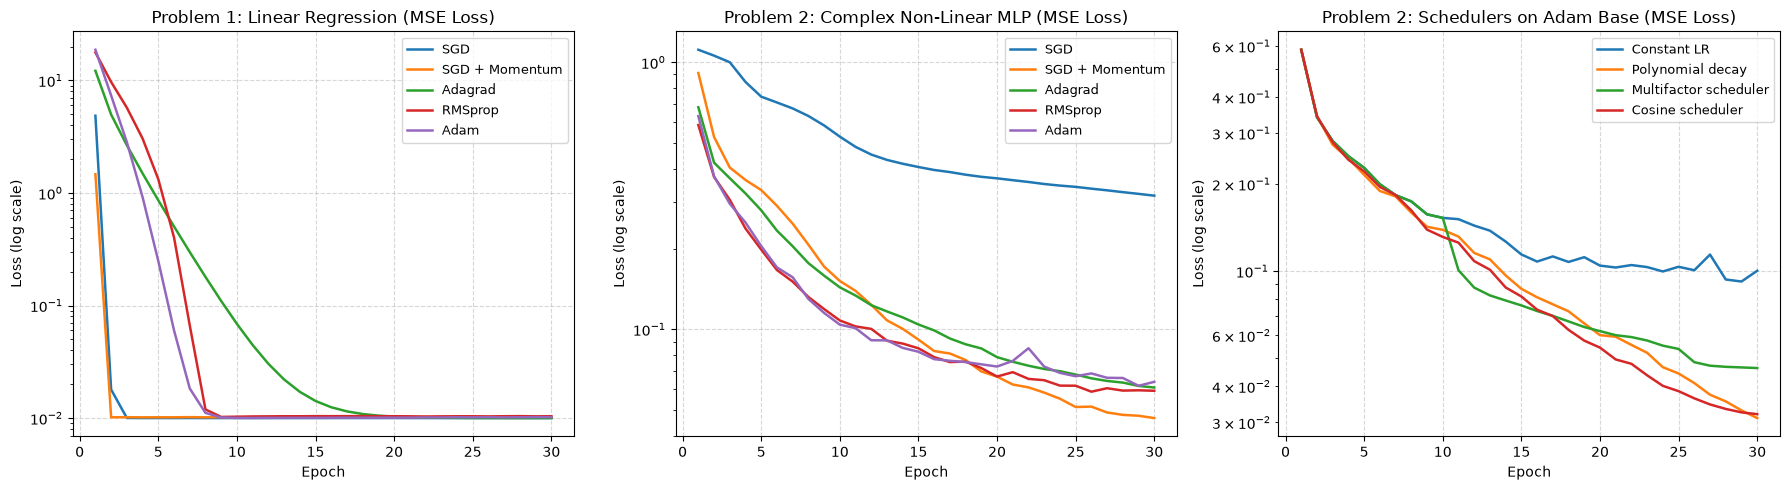

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Optimizers on Dataset 1 (Linear)
for name, losses in results1.items():
    axes[0].plot(range(1, EPOCHS + 1), losses, label=name, linewidth=1.8)
axes[0].set_yscale('log')
axes[0].set_title("Problem 1: Linear Regression (MSE Loss)")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss (log scale)")
axes[0].grid(True, linestyle="--", alpha=0.5)
axes[0].legend(fontsize=9)

# Plot 2: Optimizers on Dataset 2 (Complex MLP)
for name, losses in results2.items():
    axes[1].plot(range(1, EPOCHS + 1), losses, label=name, linewidth=1.8)
axes[1].set_yscale('log')
axes[1].set_title("Problem 2: Complex Non-Linear MLP (MSE Loss)")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss (log scale)")
axes[1].grid(True, linestyle="--", alpha=0.5)
axes[1].legend(fontsize=9)

# Plot 3: Schedulers on Dataset 2 (Adam Base)
for name, losses in scheduler_results2.items():
    axes[2].plot(range(1, EPOCHS + 1), losses, label=name, linewidth=1.8)
axes[2].set_yscale('log')
axes[2].set_title("Problem 2: Schedulers on Adam Base (MSE Loss)")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Loss (log scale)")
axes[2].grid(True, linestyle="--", alpha=0.5)
axes[2].legend(fontsize=9)

plt.tight_layout()
plt.show()

In [10]:
optimizer_configs = {
    "SGD":                  {"type": optim.SGD,      "lr": 0.01, "weight_decay": 1e-4},
    "SGD + Momentum":       {"type": optim.SGD,      "lr": 0.01, "momentum": 0.9, "weight_decay": 1e-4},
    "Adagrad":              {"type": optim.Adagrad,  "lr": 0.1,  "weight_decay": 1e-4},
    "RMSprop":              {"type": optim.RMSprop,  "lr": 0.005, "alpha": 0.99, "weight_decay": 1e-4},
    "Adam":                 {"type": optim.Adam,     "lr": 0.01, "betas": (0.9, 0.999), "weight_decay": 1e-4}
}

# 2. Definición de Schedulers
schedulers = {
    "Constant LR":           (None, None),
    "Polynomial decay":      (optim.lr_scheduler.PolynomialLR, {"total_iters": EPOCHS, "power": 1.0}),
    "Multifactor scheduler": (optim.lr_scheduler.MultiStepLR, {"milestones": [10, 20], "gamma": 0.1}),
    "Cosine scheduler":      (optim.lr_scheduler.CosineAnnealingLR, {"T_max": EPOCHS, "eta_min": 1e-4}),
}

# Diccionarios para almacenar todas las combinaciones
grid_losses = {}
grid_lrs = {}

# 3. Bucle Grid Search (Todas las combinaciones)
for opt_name, opt_config in optimizer_configs.items():
    for sched_name, (sched_cls, sched_kwargs) in schedulers.items():
        
        # Etiqueta única para identificar la combinación
        combo_name = f"{opt_name} | {sched_name}"
        print(f"Entrenando: {combo_name}...")
        
        losses, lrs = train_model(
            NonLinearMLP, 
            train_loader2, 
            opt_config,
            scheduler_cls=sched_cls, 
            scheduler_kwargs=sched_kwargs, 
            epochs=EPOCHS
        )
        
        grid_losses[combo_name] = losses
        grid_lrs[combo_name] = lrs

Entrenando: SGD | Constant LR...
Entrenando: SGD | Polynomial decay...
Entrenando: SGD | Multifactor scheduler...
Entrenando: SGD | Cosine scheduler...
Entrenando: SGD + Momentum | Constant LR...
Entrenando: SGD + Momentum | Polynomial decay...
Entrenando: SGD + Momentum | Multifactor scheduler...
Entrenando: SGD + Momentum | Cosine scheduler...
Entrenando: Adagrad | Constant LR...
Entrenando: Adagrad | Polynomial decay...
Entrenando: Adagrad | Multifactor scheduler...
Entrenando: Adagrad | Cosine scheduler...
Entrenando: RMSprop | Constant LR...
Entrenando: RMSprop | Polynomial decay...
Entrenando: RMSprop | Multifactor scheduler...
Entrenando: RMSprop | Cosine scheduler...
Entrenando: Adam | Constant LR...
Entrenando: Adam | Polynomial decay...
Entrenando: Adam | Multifactor scheduler...
Entrenando: Adam | Cosine scheduler...


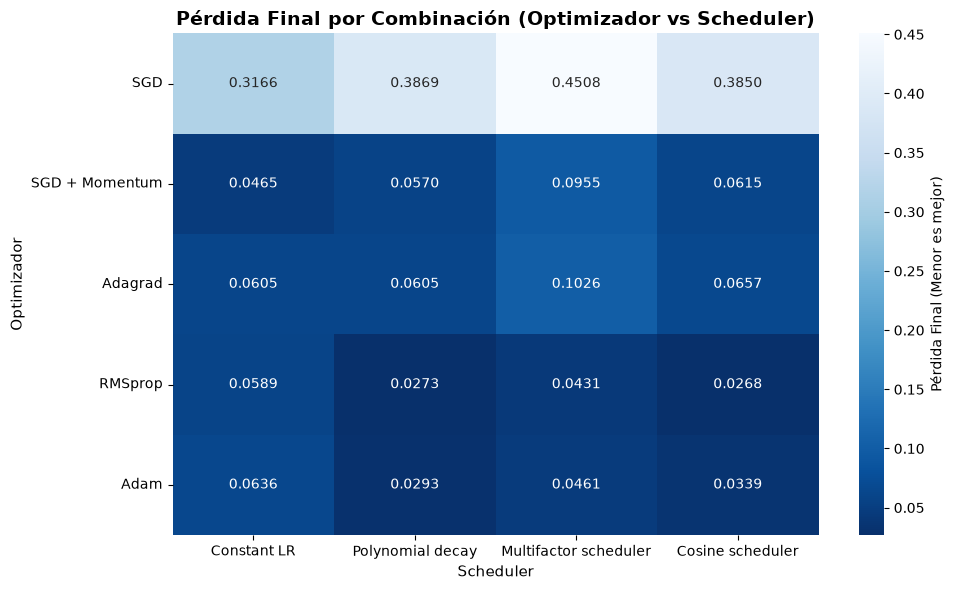

🏆 LA MEJOR CONFIGURACIÓN ES: RMSprop + Cosine scheduler (Loss: 0.0268)


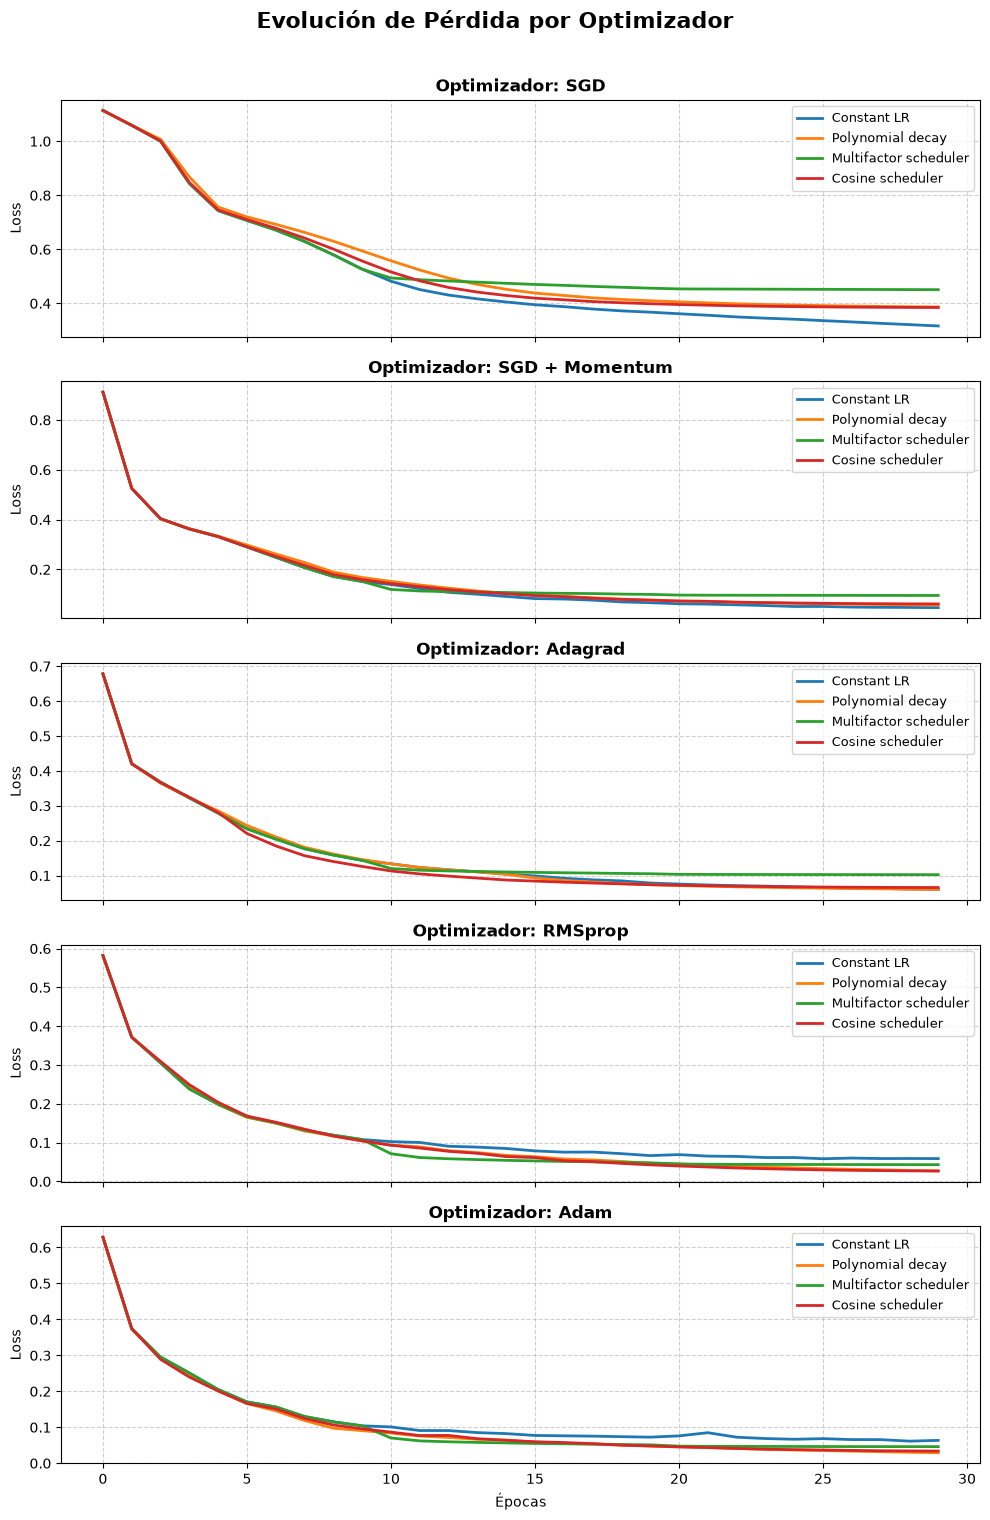

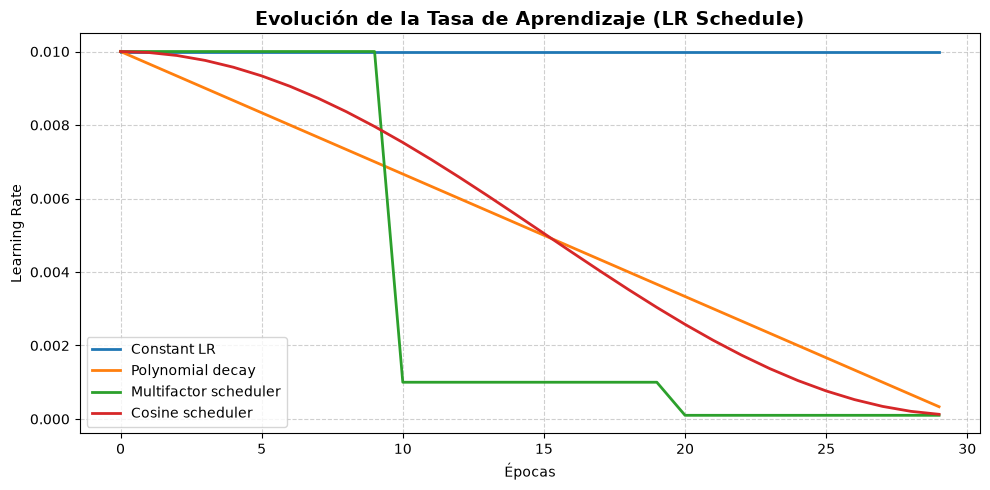

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Preparar matriz de Pérdida Final (Final Loss)
opts = list(optimizer_configs.keys())
scheds = list(schedulers.keys())

# Crear una matriz para el heatmap
final_loss_matrix = np.zeros((len(opts), len(scheds)))

for i, opt in enumerate(opts):
    for j, sched in enumerate(scheds):
        combo_name = f"{opt} | {sched}"
        # Tomamos la última pérdida registrada (época 30)
        final_loss_matrix[i, j] = grid_losses[combo_name][-1]

# Crear DataFrame para Seaborn
df_heatmap = pd.DataFrame(final_loss_matrix, index=opts, columns=scheds)

# -------------------------------------------------------------------
# VISUALIZACIÓN 1: MAPA DE CALOR DE PÉRDIDA FINAL
# -------------------------------------------------------------------
plt.figure(figsize=(10, 6))
sns.heatmap(df_heatmap, annot=True, fmt=".4f", cmap="Blues_r", cbar_kws={'label': 'Pérdida Final (Menor es mejor)'})
plt.title("Pérdida Final por Combinación (Optimizador vs Scheduler)", fontsize=14, fontweight='bold')
plt.xlabel("Scheduler", fontsize=11)
plt.ylabel("Optimizador", fontsize=11)
plt.tight_layout()
plt.show()

# Identificar la combinación ganadora
best_combo = df_heatmap.stack().idxmin()
best_loss = df_heatmap.stack().min()
print(f"🏆 LA MEJOR CONFIGURACIÓN ES: {best_combo[0]} + {best_combo[1]} (Loss: {best_loss:.4f})")

# -------------------------------------------------------------------
# VISUALIZACIÓN 2: CURVAS DE PÉRDIDA POR OPTIMIZADOR
# -------------------------------------------------------------------
fig, axes = plt.subplots(len(opts), 1, figsize=(10, 3 * len(opts)), sharex=True)

for i, opt in enumerate(opts):
    ax = axes[i]
    for sched in scheds:
        combo_name = f"{opt} | {sched}"
        ax.plot(grid_losses[combo_name], label=sched, linewidth=2)
    
    ax.set_title(f"Optimizador: {opt}", fontweight='bold')
    ax.set_ylabel("Loss")
    ax.grid(True, linestyle="--", alpha=0.6)
    ax.legend(loc="upper right", fontsize=9)

axes[-1].set_xlabel("Épocas")
plt.suptitle("Evolución de Pérdida por Optimizador", fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

# -------------------------------------------------------------------
# VISUALIZACIÓN 3: HISTORIAL DE LEARNING RATES
# -------------------------------------------------------------------
plt.figure(figsize=(10, 5))
for sched in scheds:
    # Usamos las LRs de Adam como referencia
    combo_name = f"Adam | {sched}"
    plt.plot(grid_lr_histories2[sched] if 'grid_lr_histories2' in locals() else grid_lrs[combo_name], 
             label=sched, linewidth=2)

plt.title("Evolución de la Tasa de Aprendizaje (LR Schedule)", fontsize=14, fontweight='bold')
plt.xlabel("Épocas")
plt.ylabel("Learning Rate")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

--- Iniciando entrenamiento en Dataset 1 (LinearModel) ---
¡Entrenamiento completado!



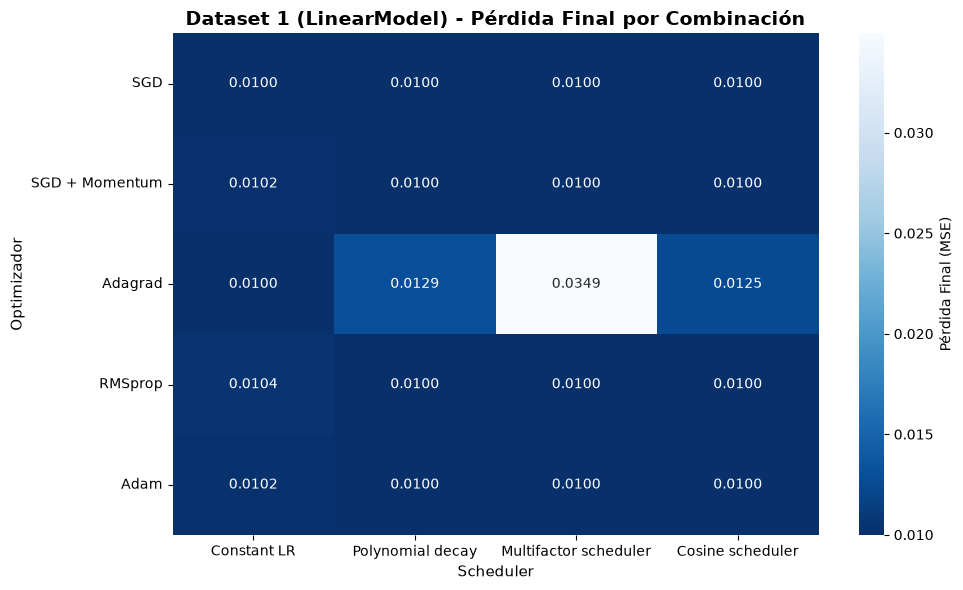

🏆 MEJOR CONFIGURACIÓN (Dataset 1): SGD + Multifactor scheduler (Loss: 0.009981)


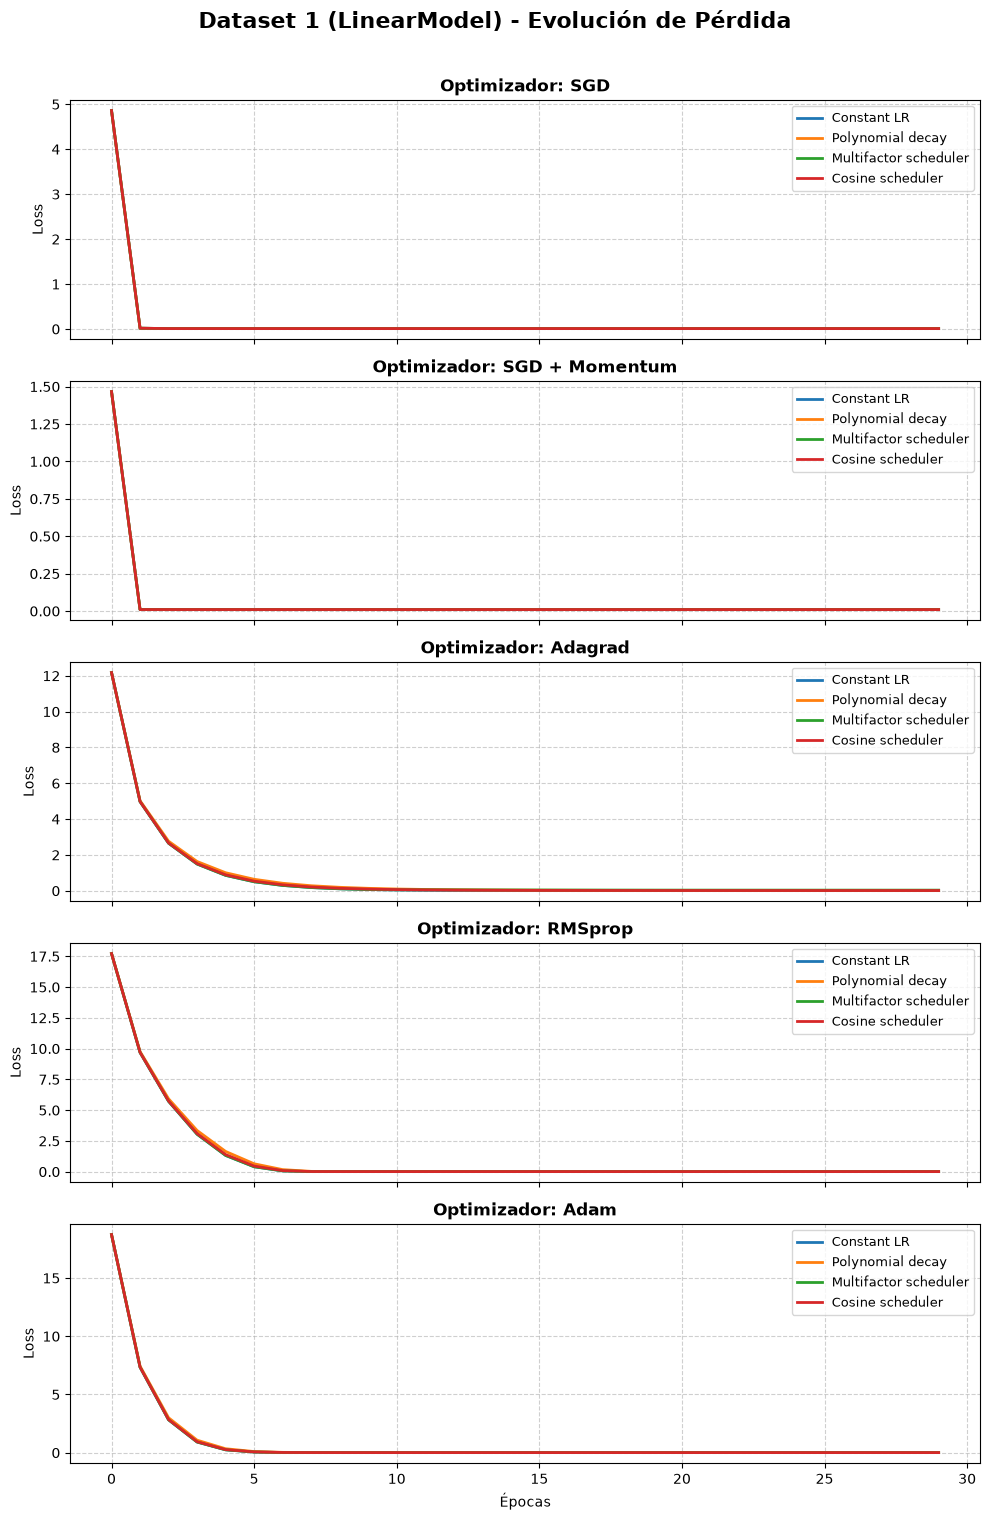

In [12]:
import torch
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

EPOCHS = 30

# 1. Definición de Optimizadores
optimizer_configs = {
    "SGD":                  {"type": optim.SGD,      "lr": 0.01, "weight_decay": 1e-4},
    "SGD + Momentum":       {"type": optim.SGD,      "lr": 0.01, "momentum": 0.9, "weight_decay": 1e-4},
    "Adagrad":              {"type": optim.Adagrad,  "lr": 0.1,  "weight_decay": 1e-4},
    "RMSprop":              {"type": optim.RMSprop,  "lr": 0.005, "alpha": 0.99, "weight_decay": 1e-4},
    "Adam":                 {"type": optim.Adam,     "lr": 0.01, "betas": (0.9, 0.999), "weight_decay": 1e-4}
}

# 2. Definición de Schedulers
schedulers = {
    "Constant LR":           (None, None),
    "Polynomial decay":      (optim.lr_scheduler.PolynomialLR, {"total_iters": EPOCHS, "power": 1.0}),
    "Multifactor scheduler": (optim.lr_scheduler.MultiStepLR, {"milestones": [10, 20], "gamma": 0.1}),
    "Cosine scheduler":      (optim.lr_scheduler.CosineAnnealingLR, {"T_max": EPOCHS, "eta_min": 1e-4}),
}

# Diccionarios para almacenar los resultados de Dataset 1
grid_losses1 = {}
grid_lrs1 = {}

# 3. Bucle Grid Search sobre Dataset 1 (LinearModel)
print("--- Iniciando entrenamiento en Dataset 1 (LinearModel) ---")
for opt_name, opt_config in optimizer_configs.items():
    for sched_name, (sched_cls, sched_kwargs) in schedulers.items():
        
        combo_name = f"{opt_name} | {sched_name}"
        
        losses, lrs = train_model(
            LinearModel, 
            train_loader1, 
            opt_config,
            scheduler_cls=sched_cls, 
            scheduler_kwargs=sched_kwargs, 
            epochs=EPOCHS
        )
        
        grid_losses1[combo_name] = losses
        grid_lrs1[combo_name] = lrs

print("¡Entrenamiento completado!\n")

# -------------------------------------------------------------------
# VISUALIZACIÓN 1: MAPA DE CALOR (Dataset 1)
# -------------------------------------------------------------------
opts = list(optimizer_configs.keys())
scheds = list(schedulers.keys())
final_loss_matrix1 = np.zeros((len(opts), len(scheds)))

for i, opt in enumerate(opts):
    for j, sched in enumerate(scheds):
        combo_name = f"{opt} | {sched}"
        final_loss_matrix1[i, j] = grid_losses1[combo_name][-1]

df_heatmap1 = pd.DataFrame(final_loss_matrix1, index=opts, columns=scheds)

plt.figure(figsize=(10, 6))
sns.heatmap(df_heatmap1, annot=True, fmt=".4f", cmap="Blues_r", cbar_kws={'label': 'Pérdida Final (MSE)'})
plt.title("Dataset 1 (LinearModel) - Pérdida Final por Combinación", fontsize=14, fontweight='bold')
plt.xlabel("Scheduler", fontsize=11)
plt.ylabel("Optimizador", fontsize=11)
plt.tight_layout()
plt.show()

# Imprimir el mejor resultado para Dataset 1
best_combo1 = df_heatmap1.stack().idxmin()
best_loss1 = df_heatmap1.stack().min()
print(f"🏆 MEJOR CONFIGURACIÓN (Dataset 1): {best_combo1[0]} + {best_combo1[1]} (Loss: {best_loss1:.6f})")

# -------------------------------------------------------------------
# VISUALIZACIÓN 2: CURVAS DE PÉRDIDA POR OPTIMIZADOR (Dataset 1)
# -------------------------------------------------------------------
fig, axes = plt.subplots(len(opts), 1, figsize=(10, 3 * len(opts)), sharex=True)

for i, opt in enumerate(opts):
    ax = axes[i]
    for sched in scheds:
        combo_name = f"{opt} | {sched}"
        ax.plot(grid_losses1[combo_name], label=sched, linewidth=2)
    
    ax.set_title(f"Optimizador: {opt}", fontweight='bold')
    ax.set_ylabel("Loss")
    ax.grid(True, linestyle="--", alpha=0.6)
    ax.legend(loc="upper right", fontsize=9)

axes[-1].set_xlabel("Épocas")
plt.suptitle("Dataset 1 (LinearModel) - Evolución de Pérdida", fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

Generando opt_comparison.png...


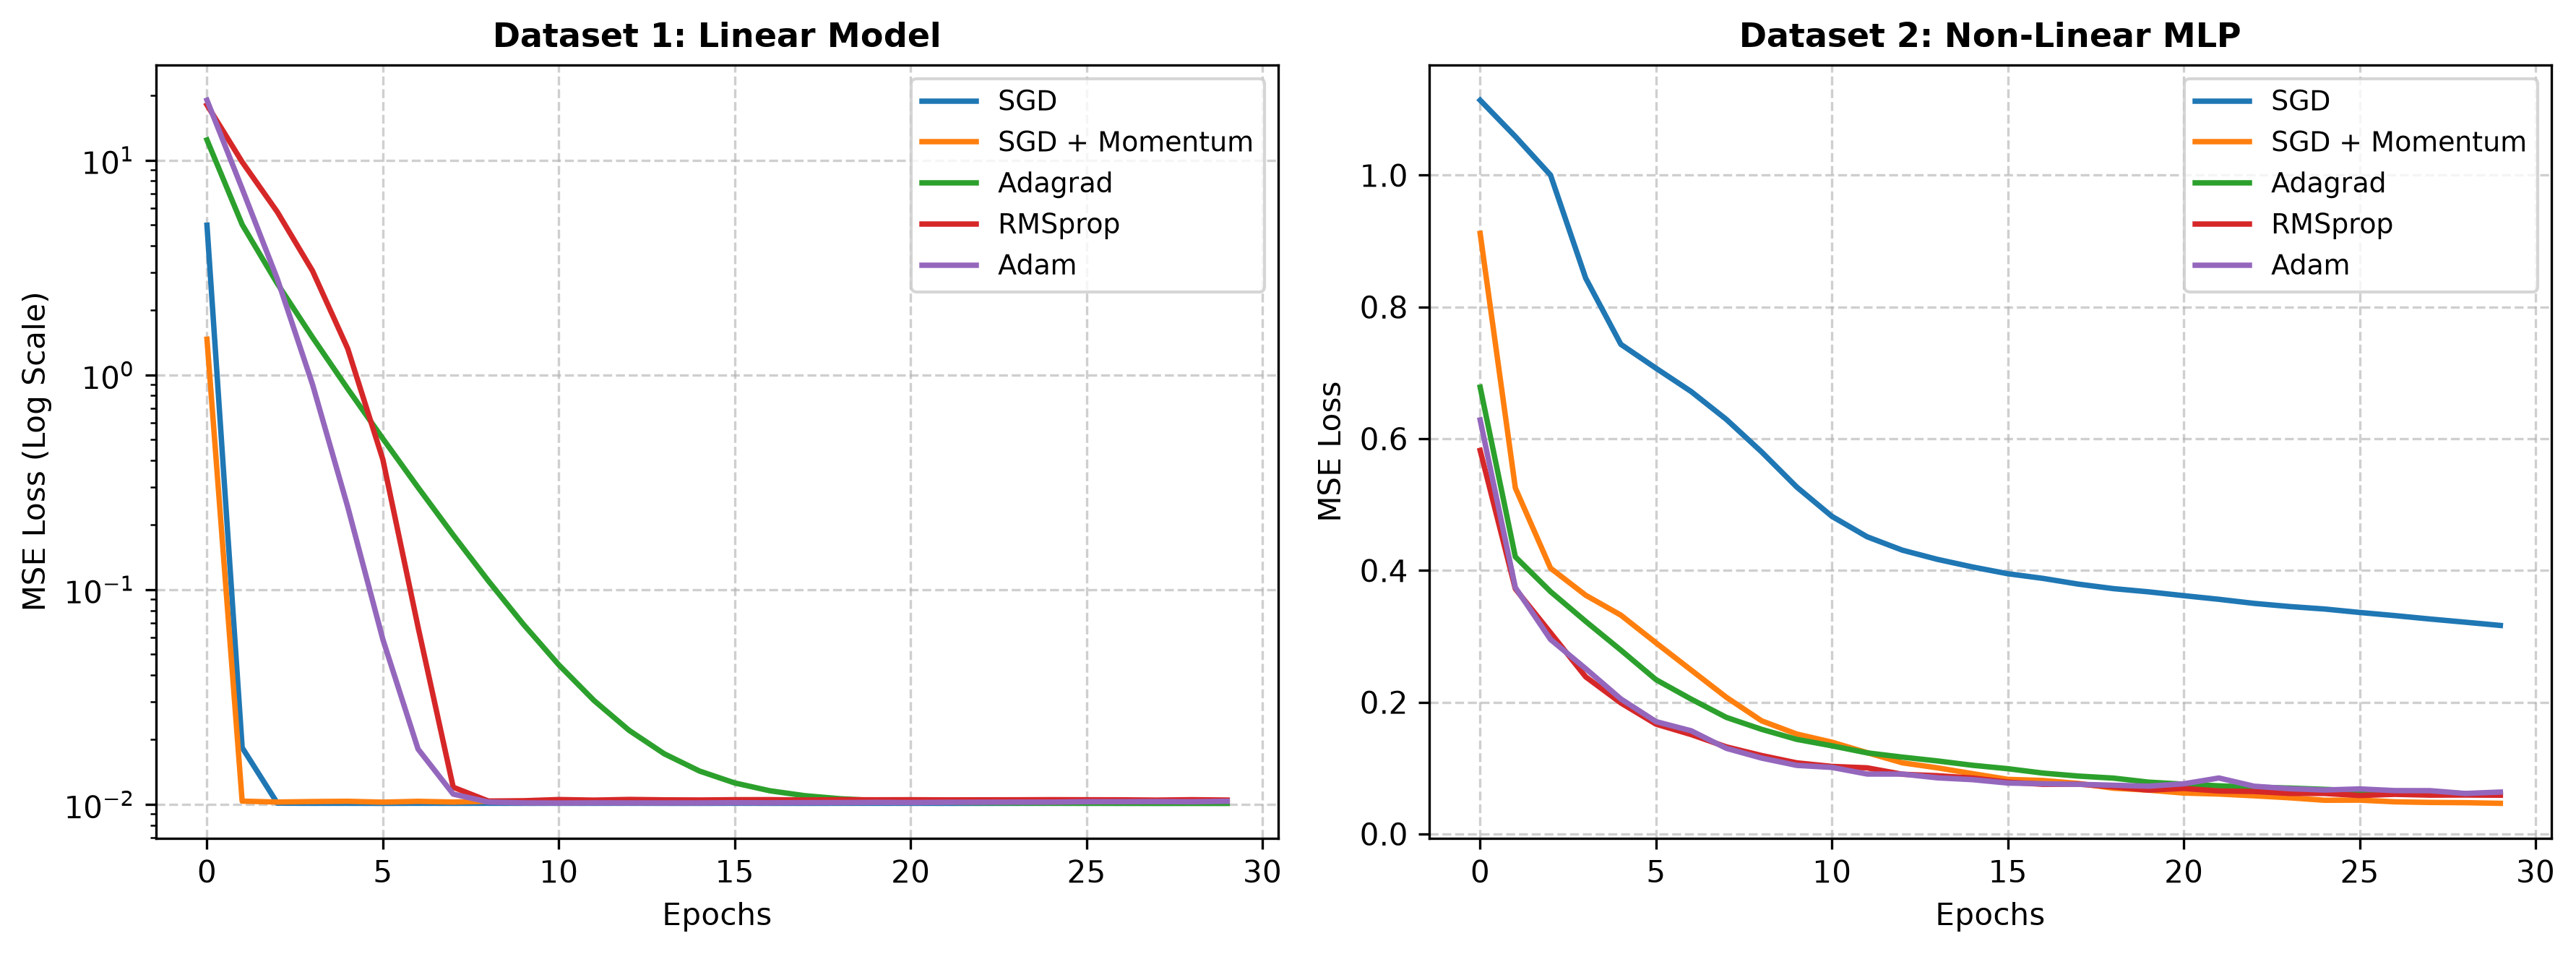

¡Guardado 'opt_comparison.png' con éxito!
Generando scheduler_comparison.png...


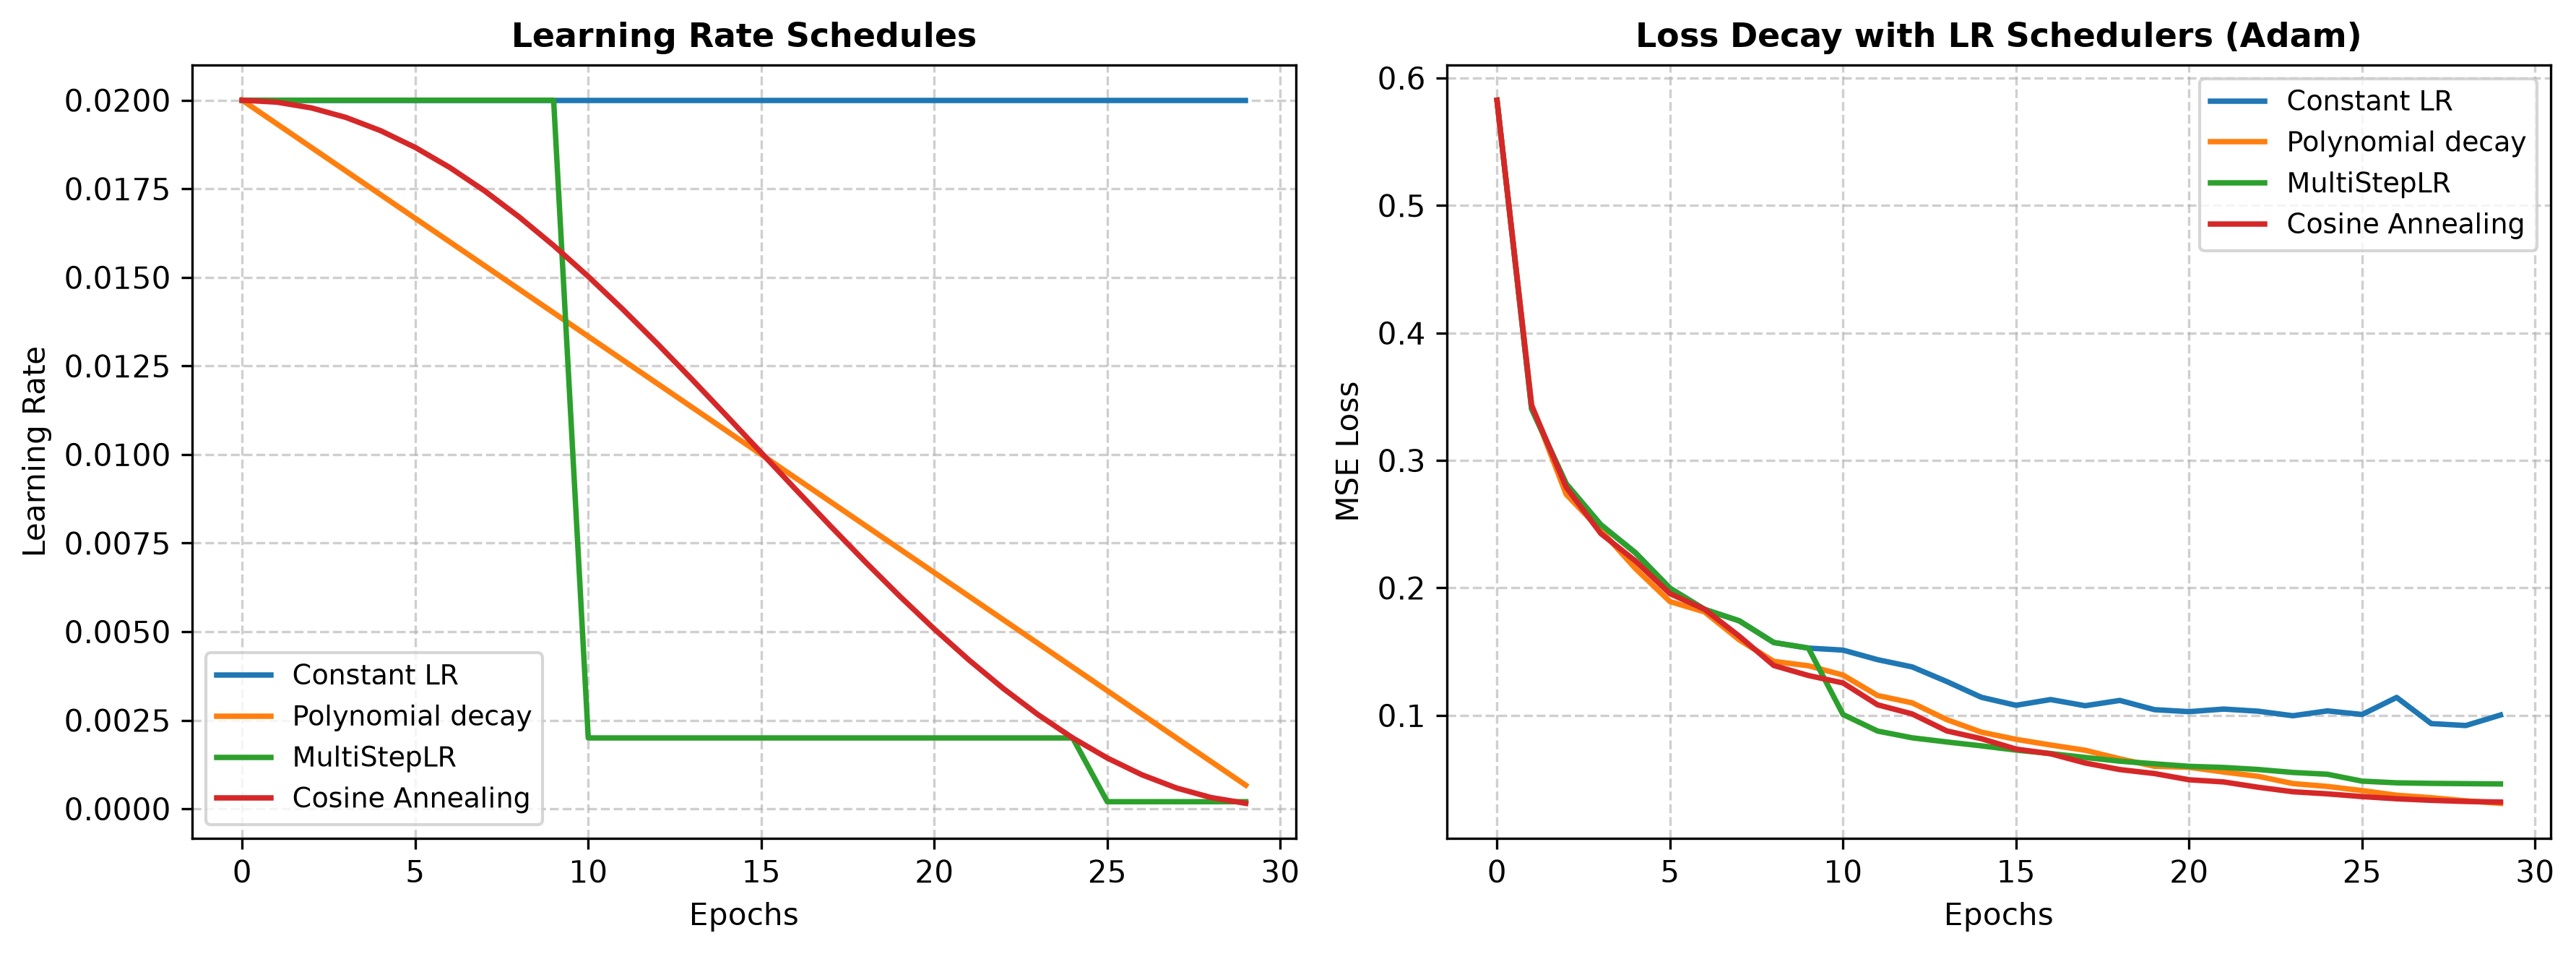

¡Guardado 'scheduler_comparison.png' con éxito!


In [13]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, TensorDataset

# --- CONFIGURACIÓN GENERAL ---
N = 10000
EPOCHS = 30
BATCH_SIZE = 64

# --- DATASETS ---
# Dataset 1: Problema Lineal
torch.manual_seed(42)
X1 = torch.randn(N, 10)
true_w = torch.randn(10, 1)
true_b = 5.0
y1 = X1 @ true_w + true_b + 0.1 * torch.randn(N, 1)
train_loader1 = DataLoader(TensorDataset(X1, y1), batch_size=BATCH_SIZE, shuffle=True)

# Dataset 2: Problema No Lineal Complejo
torch.manual_seed(0)
X2 = torch.randn(N, 20)
y2 = (
    torch.sin(X2[:, 0] * X2[:, 1]) +
    torch.log(torch.abs(X2[:, 2]) + 1) * X2[:, 3] +
    torch.cos(X2[:, 4] + X2[:, 5]**2) +
    0.1 * torch.randn(N)
).unsqueeze(1)
train_loader2 = DataLoader(TensorDataset(X2, y2), batch_size=BATCH_SIZE, shuffle=True)

# --- ARQUITECTURAS DE MODELO ---
class LinearModel(nn.Module):
    def __init__(self, in_features=10):
        super().__init__()
        self.linear = nn.Linear(in_features, 1)
    def forward(self, x):
        return self.linear(x)

class NonLinearMLP(nn.Module):
    def __init__(self, in_features=20):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_features, 64), nn.ReLU(),
            nn.Linear(64, 32), nn.ReLU(),
            nn.Linear(32, 16), nn.ReLU(),
            nn.Linear(16, 1)
        )
    def forward(self, x):
        return self.net(x)

# --- BUCLE DE ENTRENAMIENTO ---
def train_model(model_cls, train_loader, opt_config, scheduler_cls=None, scheduler_kwargs=None, epochs=30):
    torch.manual_seed(42)
    model = model_cls()
    criterion = nn.MSELoss()
    
    opt_type = opt_config['type']
    opt_kwargs = {k: v for k, v in opt_config.items() if k != 'type'}
    optimizer = opt_type(model.parameters(), **opt_kwargs)
    
    scheduler = scheduler_cls(optimizer, **(scheduler_kwargs or {})) if scheduler_cls else None
        
    epoch_losses, lr_history = [], []

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        for X_batch, y_batch in train_loader:
            optimizer.zero_grad()
            predictions = model(X_batch)
            loss = criterion(predictions, y_batch)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * X_batch.size(0)
            
        epoch_loss = running_loss / len(train_loader.dataset)
        epoch_losses.append(epoch_loss)
        lr_history.append(optimizer.param_groups[0]['lr'])
        
        if scheduler:
            scheduler.step()
                
    return epoch_losses, lr_history

# ==============================================================================
# 1. GENERAR opt_comparison.png
# ==============================================================================
print("Generando opt_comparison.png...")

optimizer_configs = {
    "SGD":            {"type": optim.SGD,      "lr": 0.01, "weight_decay": 1e-4},
    "SGD + Momentum": {"type": optim.SGD,      "lr": 0.01, "momentum": 0.9, "weight_decay": 1e-4},
    "Adagrad":        {"type": optim.Adagrad,  "lr": 0.1,  "weight_decay": 1e-4},
    "RMSprop":        {"type": optim.RMSprop,  "lr": 0.005, "alpha": 0.99, "weight_decay": 1e-4},
    "Adam":           {"type": optim.Adam,     "lr": 0.01, "betas": (0.9, 0.999), "weight_decay": 1e-4}
}

results1 = {name: train_model(LinearModel, train_loader1, cfg, epochs=EPOCHS)[0] for name, cfg in optimizer_configs.items()}
results2 = {name: train_model(NonLinearMLP, train_loader2, cfg, epochs=EPOCHS)[0] for name, cfg in optimizer_configs.items()}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), dpi=300)

# Panel 1: Problema Lineal
for name, losses in results1.items():
    ax1.plot(losses, label=name, linewidth=1.8)
ax1.set_title("Dataset 1: Linear Model", fontsize=11, fontweight='bold')
ax1.set_xlabel("Epochs", fontsize=10)
ax1.set_ylabel("MSE Loss (Log Scale)", fontsize=10)
ax1.set_yscale("log")
ax1.grid(True, linestyle="--", alpha=0.6)
ax1.legend(fontsize=9)

# Panel 2: Problema No Lineal
for name, losses in results2.items():
    ax2.plot(losses, label=name, linewidth=1.8)
ax2.set_title("Dataset 2: Non-Linear MLP", fontsize=11, fontweight='bold')
ax2.set_xlabel("Epochs", fontsize=10)
ax2.set_ylabel("MSE Loss", fontsize=10)
ax2.grid(True, linestyle="--", alpha=0.6)
ax2.legend(fontsize=9)

plt.tight_layout()
plt.savefig("opt_comparison.png", dpi=300, bbox_inches='tight')
plt.show()
print("¡Guardado 'opt_comparison.png' con éxito!")

# ==============================================================================
# 2. GENERAR scheduler_comparison.png
# ==============================================================================
print("Generando scheduler_comparison.png...")

base_adam_config = {"type": optim.Adam, "lr": 0.02, "weight_decay": 1e-4}
schedulers = {
    "Constant LR":       (None, None),
    "Polynomial decay":  (optim.lr_scheduler.PolynomialLR, {"total_iters": EPOCHS, "power": 1.0}),
    "MultiStepLR":       (optim.lr_scheduler.MultiStepLR, {"milestones": [10, 25], "gamma": 0.1}),
    "Cosine Annealing":  (optim.lr_scheduler.CosineAnnealingLR, {"T_max": EPOCHS, "eta_min": 1e-4}),
}

sched_losses, sched_lrs = {}, {}
for name, (s_cls, s_kwargs) in schedulers.items():
    losses, lrs = train_model(NonLinearMLP, train_loader2, base_adam_config, scheduler_cls=s_cls, scheduler_kwargs=s_kwargs, epochs=EPOCHS)
    sched_losses[name] = losses
    sched_lrs[name] = lrs

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), dpi=300)

# Panel 1: Evolución del Learning Rate
for name, lrs in sched_lrs.items():
    ax1.plot(lrs, label=name, linewidth=1.8)
ax1.set_title("Learning Rate Schedules", fontsize=11, fontweight='bold')
ax1.set_xlabel("Epochs", fontsize=10)
ax1.set_ylabel("Learning Rate", fontsize=10)
ax1.grid(True, linestyle="--", alpha=0.6)
ax1.legend(fontsize=9)

# Panel 2: Evolución de Pérdida
for name, losses in sched_losses.items():
    ax2.plot(losses, label=name, linewidth=1.8)
ax2.set_title("Loss Decay with LR Schedulers (Adam)", fontsize=11, fontweight='bold')
ax2.set_xlabel("Epochs", fontsize=10)
ax2.set_ylabel("MSE Loss", fontsize=10)
ax2.grid(True, linestyle="--", alpha=0.6)
ax2.legend(fontsize=9)

plt.tight_layout()
plt.savefig("scheduler_comparison.png", dpi=300, bbox_inches='tight')
plt.show()
print("¡Guardado 'scheduler_comparison.png' con éxito!")